In [1]:

from itertools import product

values = [10, 4, 7, 5, 8]
weights = [5, 3, 4, 2, 6]
capacity = 15

best_value = 0
best_items = []
best_weight = 0

for selection in product([0, 1], repeat=5):
    total_weight = sum(
        selection[i] * weights[i] for i in range(5)
    )
    total_value = sum(
        selection[i] * values[i] for i in range(5)
    )

    if total_weight <= capacity and total_value > best_value:
        best_value = total_value
        best_weight = total_weight
        best_items = [
            i + 1 for i in range(5) if selection[i] == 1
        ]

print("Selected items:", best_items)
print("Maximum value:", best_value)
print("Total weight:", best_weight)
print("Capacity:", capacity)


Selected items: [1, 2, 3, 4]
Maximum value: 26
Total weight: 14
Capacity: 15


In [4]:
%pip install -q "qiskit>=1.2,<2.0" "qiskit-aer>=0.15" "qiskit-optimization>=0.6" "networkx" "matplotlib" "pandas"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 12.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 82.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 96.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 71.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 19.7 MB/s eta 0:00:00


In [2]:
import os
folders = [
    "QFF-Knapsack/processors",
    "QFF-Knapsack/src",
    "QFF-Knapsack/results/tables",
    "QFF-Knapsack/results/figures"
]
for folder in folders:
  os.makedirs(folder,exist_ok=True)
  print("Project folders created successfully")

Project folders created successfully
Project folders created successfully
Project folders created successfully
Project folders created successfully


In [5]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

values = [10, 4, 7, 5, 8]
weights = [5, 3, 4, 2, 6]
capacity = 15

# Create the optimization problem
qp = QuadraticProgram("Knapsack")

for i in range(len(values)):
    qp.binary_var(name=f"x{i}")

# Maximize the total value
linear = {f"x{i}": values[i] for i in range(len(values))}

qp.maximize(linear=linear)

# Add the weight constraint
qp.linear_constraint(
    linear={f"x{i}": weights[i] for i in range(len(weights))},
    sense="<=",
    rhs=capacity,
    name="capacity"
)

print(qp.prettyprint())

# Convert the constrained problem to QUBO
converter = QuadraticProgramToQubo()
qubo = converter.convert(qp)

print("\nQUBO model:")
print(qubo.prettyprint())

Problem name: Knapsack

Maximize
  10*x0 + 4*x1 + 7*x2 + 5*x3 + 8*x4

Subject to
  Linear constraints (1)
    5*x0 + 3*x1 + 4*x2 + 2*x3 + 6*x4 <= 15  'capacity'

  Binary variables (5)
    x0 x1 x2 x3 x4


QUBO model:
Problem name: Knapsack

Minimize
  35*capacity@int_slack@0^2 + 140*capacity@int_slack@0*capacity@int_slack@1
  + 280*capacity@int_slack@0*capacity@int_slack@2
  + 560*capacity@int_slack@0*capacity@int_slack@3 + 140*capacity@int_slack@1^2
  + 560*capacity@int_slack@1*capacity@int_slack@2
  + 1120*capacity@int_slack@1*capacity@int_slack@3 + 560*capacity@int_slack@2^2
  + 2240*capacity@int_slack@2*capacity@int_slack@3 + 2240*capacity@int_slack@3^2
  + 350*x0*capacity@int_slack@0 + 700*x0*capacity@int_slack@1
  + 1400*x0*capacity@int_slack@2 + 2800*x0*capacity@int_slack@3 + 875*x0^2
  + 1050*x0*x1 + 1400*x0*x2 + 700*x0*x3 + 2100*x0*x4
  + 210*x1*capacity@int_slack@0 + 420*x1*capacity@int_slack@1
  + 840*x1*capacity@int_slack@2 + 1680*x1*capacity@int_slack@3 + 315*x1^2
  + 840

In [6]:
%pip install qiskit qiskit-aer qiskit-algorithms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 7.5 MB/s eta 0:00:00


In [7]:
from itertools import product

values = [10, 4, 7, 5, 8]
weights = [5, 3, 4, 2, 6]
capacity = 15

best_value = 0
best_items = []
best_weight = 0

for bits in product([0, 1], repeat=len(values)):
    total_weight = sum(
        bits[i] * weights[i] for i in range(len(values))
    )
    total_value = sum(
        bits[i] * values[i] for i in range(len(values))
    )

    if total_weight <= capacity and total_value > best_value:
        best_value = total_value
        best_items = [i + 1 for i, bit in enumerate(bits) if bit]
        best_weight = total_weight

print("Best item numbers:", best_items)
print("Total weight:", best_weight)
print("Total value:", best_value)

Best item numbers: [1, 2, 3, 4]
Total weight: 14
Total value: 26


In [8]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import Sampler

print("All QAOA imports successful!")

All QAOA imports successful!


In [9]:
print("Original decision variables:", len(values))
print("QUBO variables:", qubo.get_num_vars())
print("QUBO variable names:", qubo.variables)

Original decision variables: 5
QUBO variables: 9
QUBO variable names: [<Variable: x0 (binary)>, <Variable: x1 (binary)>, <Variable: x2 (binary)>, <Variable: x3 (binary)>, <Variable: x4 (binary)>, <Variable: capacity@int_slack@0 (binary)>, <Variable: capacity@int_slack@1 (binary)>, <Variable: capacity@int_slack@2 (binary)>, <Variable: capacity@int_slack@3 (binary)>]


In [11]:
%pip install --upgrade qiskit qiskit-aer qiskit-algorithms qiskit-optimization

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 49.2 MB/s eta 0:00:00
  Attempting uninstall: qiskit
    Found existing installation: qiskit 1.4.6
    Uninstalling qiskit-1.4.6:
      Successfully uninstalled qiskit-1.4.6


In [14]:
import qiskit
import qiskit_aer
import qiskit_algorithms
import qiskit_optimization

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("Qiskit Algorithms:", qiskit_algorithms.__version__)
print("Qiskit Optimization:", qiskit_optimization.__version__)

Qiskit: 1.4.6
Qiskit Aer: 0.17.2
Qiskit Algorithms: 0.4.0
Qiskit Optimization: 0.7.0


In [16]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
print("Sampler created successfully!")

Sampler created successfully!


In [17]:
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=100),
    reps=1
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(qubo)

print("QAOA solution:", result.x)
print("QUBO objective:", result.fval)

QAOA solution: [1. 0. 0. 1. 1. 0. 1. 0. 0.]
QUBO objective: -23.0


In [18]:
values = [10, 4, 7, 5, 8]
weights = [5, 3, 4, 2, 6]
capacity = 15

# First 5 bits are the original item-selection variables
selected_bits = [int(round(bit)) for bit in result.x[:len(values)]]

selected_items = [
    i + 1 for i, bit in enumerate(selected_bits) if bit == 1
]

total_weight = sum(
    weights[i] * selected_bits[i] for i in range(len(values))
)

total_value = sum(
    values[i] * selected_bits[i] for i in range(len(values))
)

print("Selected item numbers:", selected_items)
print("Total weight:", total_weight)
print("Total value:", total_value)
print("Capacity:", capacity)
print("Feasible solution:", total_weight <= capacity)

Selected item numbers: [1, 4, 5]
Total weight: 13
Total value: 23
Capacity: 15
Feasible solution: True


In [19]:
import pandas as pd

comparison = pd.DataFrame({
    "Method": ["Classical Exact", "QAOA (reps=1)"],
    "Selected Items": ["[1, 2, 3, 4]", str(selected_items)],
    "Total Weight": [14, total_weight],
    "Total Value": [26, total_value],
    "Feasible": [True, total_weight <= capacity]
})

comparison

,Method,Selected Items,Total Weight,Total Value,Feasible
0,Classical Exact,"[1, 2, 3, 4]",14,26,True
1,QAOA (reps=1),"[1, 4, 5]",13,23,True


In [20]:
classical_best = 26
qaoa_value = total_value

quality = (qaoa_value / classical_best) * 100

print(f"QAOA solution quality: {quality:.2f}%")
print(f"Gap from classical optimum: {classical_best - qaoa_value}")

QAOA solution quality: 88.46%
Gap from classical optimum: 3


In [21]:
import os

os.makedirs("QFF-Knapsack/results/tables", exist_ok=True)

# Save comparison table
comparison.to_csv(
    "QFF-Knapsack/results/tables/classical_vs_qaoa.csv",
    index=False
)

# Save QAOA metrics
metrics = pd.DataFrame({
    "Metric": [
        "Classical best value",
        "QAOA value",
        "QAOA solution quality (%)",
        "Gap from classical optimum",
        "QAOA reps",
        "QAOA feasible"
    ],
    "Result": [
        classical_best,
        qaoa_value,
        round(quality, 2),
        classical_best - qaoa_value,
        1,
        total_weight <= capacity
    ]
})

metrics.to_csv(
    "QFF-Knapsack/results/tables/qaoa_metrics.csv",
    index=False
)

print("Results saved successfully!")
print("1. classical_vs_qaoa.csv")
print("2. qaoa_metrics.csv")

Results saved successfully!
1. classical_vs_qaoa.csv
2. qaoa_metrics.csv


In [22]:
from google.colab import files

files.download(
    "QFF-Knapsack/results/tables/classical_vs_qaoa.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
files.download(
    "QFF-Knapsack/results/tables/qaoa_metrics.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

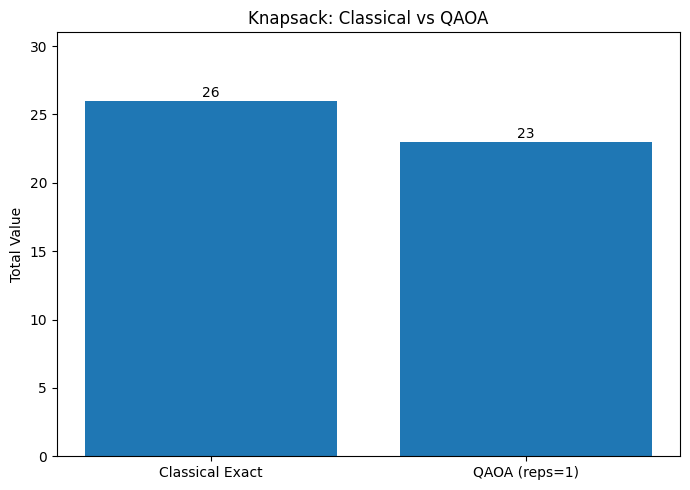

Graph saved successfully!


In [25]:
import matplotlib.pyplot as plt
import os

os.makedirs("QFF-Knapsack/results/figures", exist_ok=True)

methods = ["Classical Exact", "QAOA (reps=1)"]
values_to_plot = [classical_best, qaoa_value]

plt.figure(figsize=(7, 5))
bars = plt.bar(methods, values_to_plot)

plt.title("Knapsack: Classical vs QAOA")
plt.ylabel("Total Value")
plt.ylim(0, max(values_to_plot) + 5)

for bar, value in zip(bars, values_to_plot):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "QFF-Knapsack/results/figures/classical_vs_qaoa.png",
    dpi=300
)
plt.show()

print("Graph saved successfully!")

In [26]:
import os

path = "QFF-Knapsack/results/figures/classical_vs_qaoa.png"

print("Graph file exists:", os.path.exists(path))
print("Current folder:", os.getcwd())

Graph file exists: True
Current folder: /content


In [27]:
import os

files = [
    "QFF-Knapsack/results/tables/classical_vs_qaoa.csv",
    "QFF-Knapsack/results/tables/qaoa_metrics.csv"
]

for file in files:
    print(file, "->", os.path.exists(file))

QFF-Knapsack/results/tables/classical_vs_qaoa.csv -> True
QFF-Knapsack/results/tables/qaoa_metrics.csv -> True


# QFF Knapsack Phase 1

## 1. Introduction

This project studies the 0/1 Knapsack optimization problem using a classical exact method and the Quantum Approximate Optimization Algorithm (QAOA).

## 2. Problem Setup

We consider 5 items with values [10, 4, 7, 5, 8] and weights [5, 3, 4, 2, 6]. The maximum capacity is 15.

## 3. Methodology

We solve the problem using a classical exact method and implement QAOA using Qiskit. The QAOA experiment is performed using a simulator.

## 4. Results

The classical exact solution gives a total value of 26. The recorded QAOA run gives a total value of 23, with selected items [1, 4, 5]. These results are from simulation, not quantum hardware.

## 5. Limitations

QAOA is stochastic, so its result may vary between runs. The current QUBO formulation also introduces slack variables, increasing the number of qubits required.

## 6. Conclusion

This project compares a classical exact solution with a QAOA simulation for a small Knapsack problem. The results illustrate both the potential and the current limitations of the quantum optimization approach.